# 2 · The three GAN designs and how good their images are

Three ways of using a GAN to add images to the 7 minority classes (training split only), each retrained at every imbalance level:

| Scenario | Design |
|---|---|
| **S1** | one conditional DCGAN trained on the 7 minority classes only |
| **S2** | one conditional DCGAN trained on all 38 classes |
| **S3** | seven separate DCGANs, one per minority class |

Every minority class is topped up to 874 images (the training median), the same target oversampling uses. All GANs use DiffAugment and 10,000 steps;
the checkpoint is chosen by KID (Kernel Inception Distance, lower is better, unbiased for small samples).

This notebook reads the saved GAN reports in `experiment/gan_results/`.

In [1]:
%matplotlib inline
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import study
from study import metrics, LEVELS, METHODS, LABEL, COLOR
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True})
pd.set_option("display.width", 140)

In [2]:
rows = []
div = json.load(open(study.GAN_RESULTS / "diversity.json"))
for sc in ["s1_cond_minority", "s2_cond_all", "s3_per_class"]:
    for lv in LEVELS:
        rep = json.load(open(study.GAN_RESULTS / f"{sc}_{lv}.json"))
        rows.append({"scenario": sc, "level": lv, "mean KID": rep["mean_kid"], "diversity": div[f"{sc}_{lv}"]["mean"]})
q = pd.DataFrame(rows)
print("KID: lower is better.  Diversity: spread of generated images relative to real ones; about 1 = as varied as real, near 0 = collapsed.")
q.pivot(index="scenario", columns="level", values=["mean KID", "diversity"])[["mean KID", "diversity"]].round(3)

KID: lower is better.  Diversity: spread of generated images relative to real ones; about 1 = as varied as real, near 0 = collapsed.


mean KID               diversity              
level                 100     30   full       100     30   full
scenario                                                       
s1_cond_minority    0.378  0.411  0.399     0.049  0.238  0.066
s2_cond_all         0.220  0.231  0.152     0.828  0.863  0.827
s3_per_class        0.081  0.067  0.110     0.860  0.940  0.813

**Reading the table:** S1 has very low diversity at every level. It **mode-collapsed**: it produces essentially one image per class whatever the random input.
It also has by far the worst KID (about 0.4, against 0.07 to 0.22 for S2 and S3), so both scores agree. The diversity score was added after seeing S1's progress
sheets, to put a number on the collapse. The study kept S1 exactly as planned and reports the collapse as a finding.

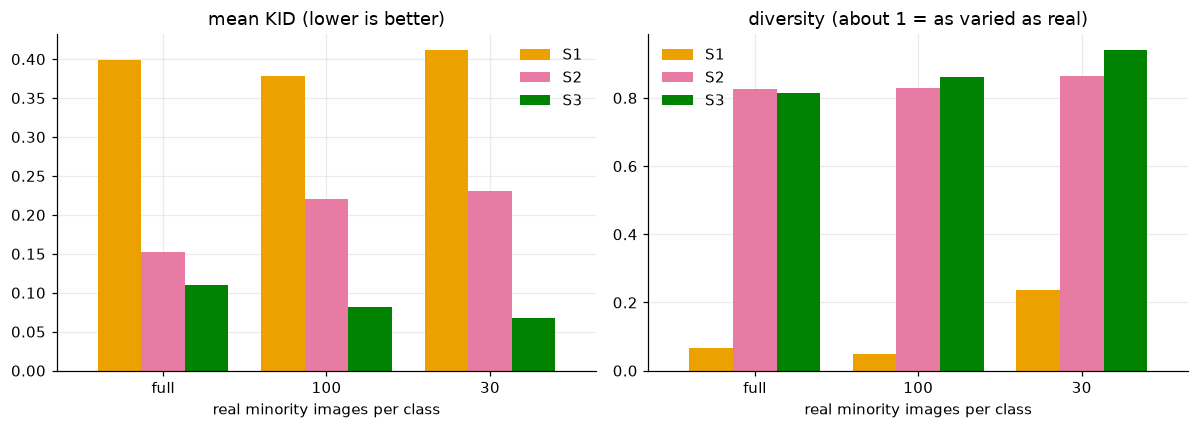

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["mean KID", "diversity"]):
    piv = q.pivot(index="level", columns="scenario", values=col).loc[LEVELS]
    piv.plot.bar(ax=ax, rot=0, color=["#eda100", "#e87ba4", "#008300"], width=.8)
    ax.set_title(col + (" (lower is better)" if col == "mean KID" else " (about 1 = as varied as real)"))
    ax.set_xlabel("real minority images per class")
    ax.legend(["S1", "S2", "S3"], frameon=False)
plt.tight_layout(); plt.show()

## What the generated images look like

Each progress sheet shows the *same fixed noise inputs* every 2,000 training steps. First S1 at the full level (collapsed, all 7 classes in one sheet), then S3 for one class (Potato healthy, the rarest).

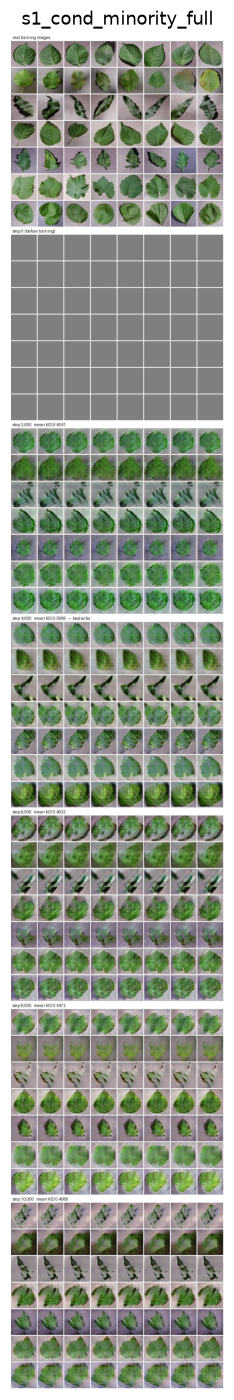

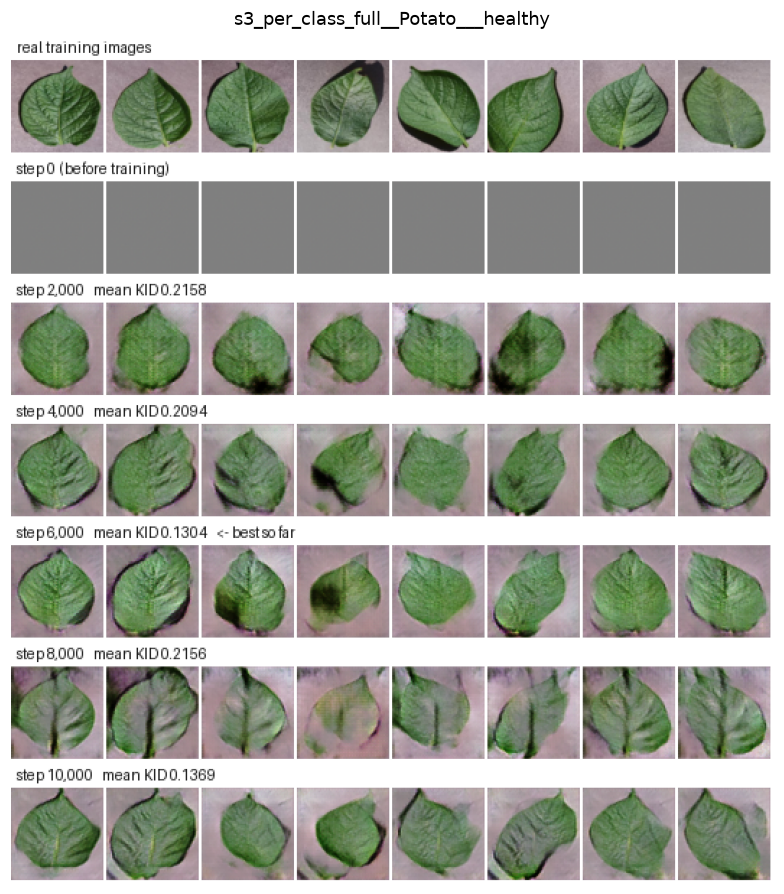

In [4]:
for name in ["s1_cond_minority_full_progress.png", "s3_per_class_full__Potato___healthy_progress.png"]:
    img = mpimg.imread(study.GAN_RESULTS / name)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(9, min(16, 9 * h / w)))
    ax.imshow(img); ax.set_title(name.replace("_progress.png", "")); ax.axis("off"); ax.grid(False)
    plt.show()

## Does S3 just memorise its training images?

For each S3 class the report measures how close each generated image is to its nearest real *training* image, and compares that with how close real training
images are to each other. The table gives the share of generated images that are closer to a real image than the closest 5% of real-to-real pairs.
Purely by chance that share would be about 0.05; values well above it mean near-copies of training photos.

In [5]:
rows = []
for lv in LEVELS:
    pc = json.load(open(study.GAN_RESULTS / f"s3_per_class_{lv}.json"))["per_class"]
    for cls, r in pc.items():
        rows.append({"level": lv, "class": cls, "share closer than real-to-real": r["memorisation"]["share_generated_closer_than_real_5pct"]})
pd.DataFrame(rows).pivot(index="class", columns="level", values="share closer than real-to-real")[LEVELS].round(3)

level,full,100,30
class,,,
Apple___Cedar_apple_rust,0.024,0.010,0.271
Grape___healthy,0.002,0.171,0.044
Peach___healthy,0.014,0.044,0.541
Potato___healthy,0.005,0.044,0.060
Raspberry___healthy,0.000,0.012,0.264
Strawberry___healthy,0.000,0.013,0.309
Tomato___Tomato_mosaic_virus,0.010,0.009,0.007


These image-quality scores are only half the story. Whether the images actually *help a classifier* is tested in
[notebook 3](3_Method_Comparison.ipynb) and, in the harshest form (the classifier sees **only** generated images of a class), in
[notebook 4](4_Follow_up_Checks.ipynb).